In [66]:
import matplotlib.pyplot as plt
import numpy as np

from anemone.forwards import *
from anemone.system import *
class VMDForward(Forward):
    geomz = None
    t2t   = None

    def __init__(self, source_height, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None, primary=False):
        tx = Loop.square(1., z=source_height)
        super().__init__(tx, receiver, times, waveform, filterfunc, t_gatewidth, tolerance)
        self.rx_dist = torch.sqrt(receiver.x**2 + receiver.y**2)
        self.t2t = None
        self.primary = primary

    def forward(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)*self.lmb**2 / c.fourpi
                self.pfield = torch.exp(-self.tmp_u0*self.pfield_dz)*self.lmb**2 / c.fourpi
                intg = rte(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                if self.primary:
                    intg += self.pfield
                return intg.squeeze()
            hkl1 = Hankel(wvlngth_integrand, 0, smp_per_decade=10, device=self.device)
            hkl1._recenter_function(self.rx_dist)
            Hr = ((hkl1.func(hkl1.lamda))@(hkl1.fc+0j))/self.rx_dist
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega.squeeze())
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier(frq_integrand, device=self.device, tolerance=self.tolerance)
            def t2t_func(t_in):
                if self.t_gatewidth is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze())*self.omega1.squeeze())
        self.dpred = Ht.real
        return self.dpred

In [67]:
tx = Loop.square(40)

In [ ]:
rx = Receiver(x=0.02)
times = torch.logspace(-8, -3, 50)
fwr = ForwardLaplace(tx, rx, times, waveform=Waveform.example())

# fwr = BstepLaplace(tx, rx, times)

fwr0 = VMDForward(1., rx, times)
fwr1 = VMDForward(1., rx, times, primary=True)

rho = torch.ones(3)*40.
thick = torch.ones(2)*40

dbdt0 = fwr0(rho, thick)
dbdt1 = fwr1(rho, thick)


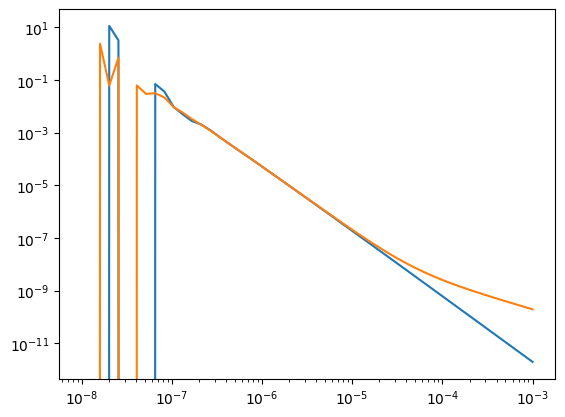

In [71]:
plt.figure()
plt.loglog(times, dbdt0)
plt.loglog(times, dbdt1)

In [255]:
def waveform_matrix_with_primary(t_in, t_out, waveform):
    t_out = t_out.to(torch.double)
    t_in  = t_in.to(torch.double)

    logT = torch.log(t_in)
    # logT = t_in
    dT = torch.diff(logT, prepend=logT[1:2]-2*logT[:1])
    # dT = logT[1]-logT[0]
    #dT = torch.roll(dT, 1)  # Shift to align with t_in

    t2t = torch.zeros(t_out.shape+(len(t_in)+1,), device=t_in.device, dtype=t_out.dtype)

    for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
        c_t_eval = t_out - t_wv
        positive_time = c_t_eval > 0.
        t2t[~positive_time , 0]  += k_wv
        # t2t[c_t_eval==0., 1]     += 0.5*k_wv
        tmp_t = torch.log(c_t_eval[positive_time])
        t2t[ positive_time, 1:]  += k_wv*lamontagne((tmp_t[:,None]-logT[None,:])/dT[None,:])
        # print(k_wv)
        
        # t_negative = -1.*c_t_eval
        # positive_time = t_negative >= 0.
        # t2t[positive_time, 1:] += k_wv*torch.nan_to_num(lamontagne((torch.log(t_negative[positive_time])[:,None]-logT[None,:])/dT[None,:]))
        # t2t[~positive_time, 0] += k_wv
    t2t[:, 1] = 0.
    return t2t

class ForwardLaplace7(ForwardLaplace):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None, t_smp_per_decade=12):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance, t_smp_per_decade)
        # self.t2t = wv_to_t(self.times, self.t_eval, waveform=self.waveform)#.to_sparse()
        self.t2t = waveform_matrix_with_primary(self.t_eval, self.times, self.waveform)

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                
                self.s_lap = s[None, None, :]
                self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz)
                # self.pfield = torch.exp(-self.lmb*self.pfield_dz)

                intg = rtelap(self.sigma, self.thick, self.s_lap, self.lmb)*self.sfield_rte
                # if self.primary:
                # intg += torch.exp(-self.lmb*self.pfield_dz)

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                # if self.waveform is not None:
                intg /= -self.s_lap
                return torch.squeeze(intg).real

            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res[None, ...] *= self.lmb / c.fourpi
            return res.swapaxes(-2,-1)
        if self.geomz is None:
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=10, tolerance=self.tolerance)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Ht, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
        else:
            Ht = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)

        self.bstep = torch.concat([self.pfield, Ht])
        # self.bstep = Ht
        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', self.bstep, self.t2t)
        else:
            return torch.einsum('...ik,...jk->...ij', self.bstep, self.t2t).squeeze()     
        
    def __call__(self, rho, thickness, primary=False):
        self.primary = primary
        self.rho = rho[..., None, None]
        if rho.ndim > thickness.ndim:
            thickness = thickness[:, None, ...]
        self.thick = thickness[..., None, None]
        return self.forward()#*c.mu0

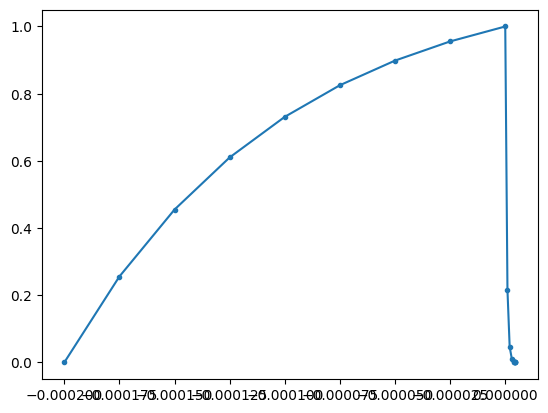

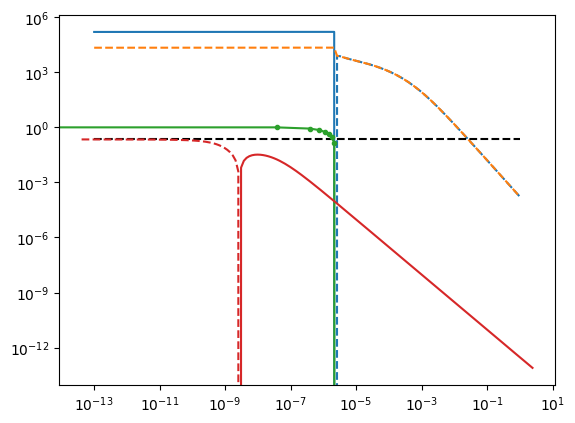

In [261]:
tx = Loop.square(3, z=0.02)
rx = Receiver(x=2., z=0.02)
times = torch.logspace(-13, 0, 150)

DEFAULT_WAVE_T = np.array([
    -2.00e-04, -1.75e-04, -1.50e-04, -1.25e-04, -1.00e-04, -7.50e-05,
    -5.00e-05, -2.50e-05,  0.00e+00,  1.00e-06,  2.00e-06,  3.00e-06,
     4.00e-06,  4.10e-06,  4.20e-06,  4.30e-06,  4.40e-06,  4.50e-06,
])
DEFAULT_WAVE_A = np.array([0.00000, 0.25582, 0.45505, 0.61022, 0.73106, 0.82517,
    0.89846, 0.95555, 1.00000, 0.21544, 0.046416, 0.01000,
    0.0021544, 0.0018478, 0.0015849, 0.0013594, 0.0011659, 0.00000,
])

plt.figure()
plt.plot(DEFAULT_WAVE_T, DEFAULT_WAVE_A, '.-')


wv0 = Waveform.example()
DEFAULT_WAVE_T = wv0.time
DEFAULT_WAVE_A = wv0.amplitude

from scipy.interpolate import interp1d
wv_int = interp1d(DEFAULT_WAVE_T, DEFAULT_WAVE_A, kind='cubic', bounds_error=False, fill_value=0.0)
wave_t = DEFAULT_WAVE_T
wave_a = DEFAULT_WAVE_A

wave_t = np.linspace(DEFAULT_WAVE_T.min(), DEFAULT_WAVE_T.max(), 3000)
wave_a = wv_int(wave_t)
t2t = fwr0.t2t


wv = Waveform(wave_t, wave_a)

fwr0 = ForwardLaplace7(tx, rx, times, waveform=wv, t_smp_per_decade=12)
fwr0.t2t = t2t
fwr1 = ForwardLaplace7(tx, rx, times, waveform=wv, t_smp_per_decade=12)
fwr1.t2t = t2t

rho   = torch.ones(3)*40.
thick = torch.ones(2)*40

from biotsavart import Loop as bsLoop, ObsPoint, calc_bfield
loop = bsLoop(tx.x.numpy(), tx.y.numpy(), tx.z.numpy())
obs = ObsPoint(rx.x.numpy(), rx.y.numpy(), rx.z.numpy())
pfield = -torch.from_numpy(calc_bfield(loop.xyz, obs.xyz)[..., 2]).reshape([1]) / c.mu0

fwr0.pfield =  pfield
fwr1.pfield = -pfield#torch.zeros(1)#0.

dbdt0 = fwr0(rho, thick)
dbdt1 = fwr1(rho, thick)
plt.figure()
plt.loglog(times, dbdt0); plt.loglog(times, -dbdt0, 'C0--')
plt.loglog(times, dbdt1); plt.loglog(times, -dbdt1, 'C1--')
plt.loglog(times, torch.ones_like(times)*torch.abs(pfield), 'k--')
plt.loglog(wave_t, wave_a, '.-')
plt.loglog(fwr0.t_eval, fwr0.bstep[1:], 'C3');plt.loglog(fwr0.t_eval, -fwr0.bstep[1:], 'C3--')

C:\Users\au646858\AppData\Local\Temp\ipykernel_13048\2178365039.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.pcolor(np.log10(np.abs(fwr0.t2t)))
C:\Users\au646858\AppData\Local\Temp\ipykernel_13048\2178365039.py:2: RuntimeWarning: divide by zero encountered in log10
  plt.pcolor(np.log10(np.abs(fwr0.t2t)))


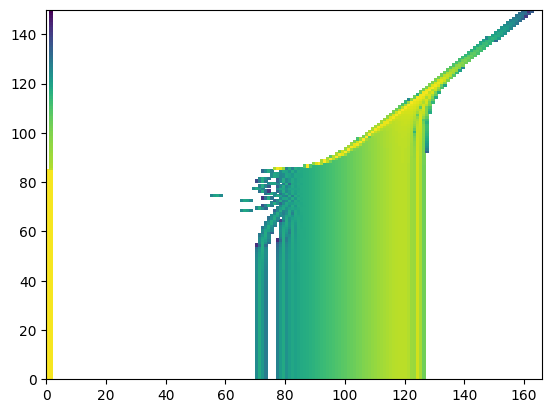

In [262]:
plt.figure()
plt.pcolor(np.log10(np.abs(fwr0.t2t)))